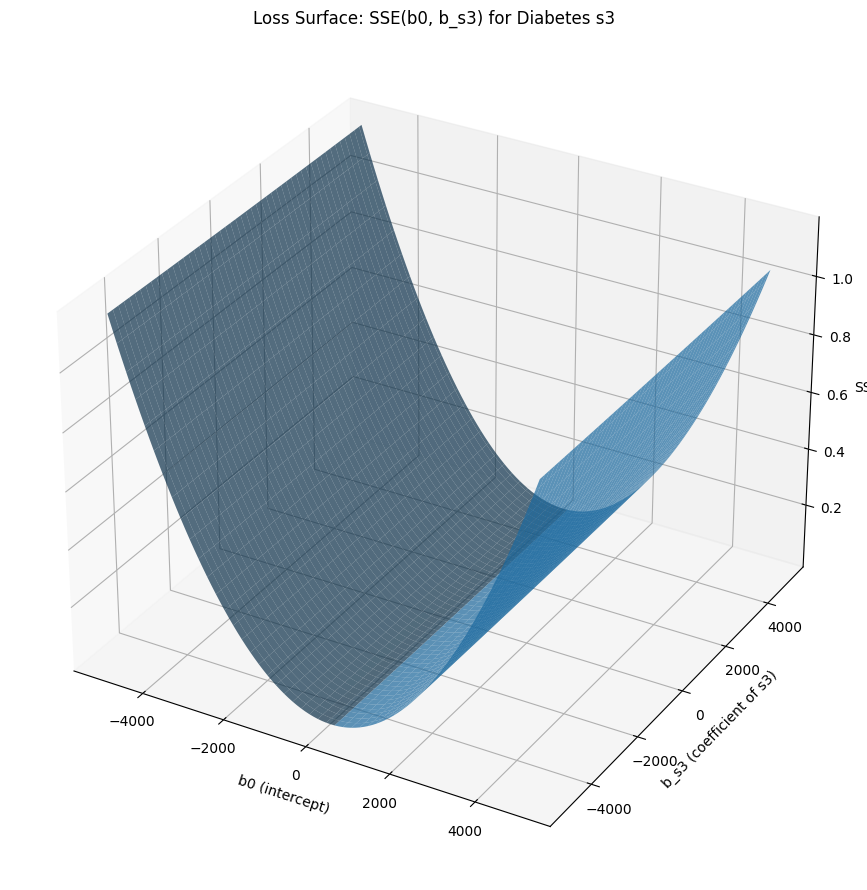

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (3D 활성화용)
from sklearn.datasets import load_diabetes

# 1. 데이터 로드
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

# s3의 컬럼 인덱스 확인
idx_s3 = feature_names.index('s3')
x_s3 = X[:, idx_s3]

# 2. b0, b_s3 값의 범위 설정
#   - 대략적인 해 주변을 보고 싶으면 아래 범위를 조정해도 됩니다.
b0_range = np.linspace(-5000, 5000, 100)
b_s3_range = np.linspace(-5000, 5000, 100)

B0, B_s3 = np.meshgrid(b0_range, b_s3_range)

# 3. 손실(SSE) 계산
#    각 (b0, b_s3)에 대해 y_pred = b0 + b_s3 * x_s3
Y_pred = B0[None, :, :] + B_s3[None, :, :] * x_s3[:, None, None]  # (n, grid, grid)
# SSE: 샘플 방향(n)에 대해 제곱합
SSE = np.sum((y[:, None, None] - Y_pred) ** 2, axis=0)

# 4. 3D plot
fig = plt.figure(figsize=(16,9))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(B0, B_s3, SSE, alpha=0.7)
ax.set_xlabel('b0 (intercept)')
ax.set_ylabel('b_s3 (coefficient of s3)')
ax.set_zlabel('SSE')
ax.set_title('Loss Surface: SSE(b0, b_s3) for Diabetes s3')

plt.tight_layout()
plt.show()


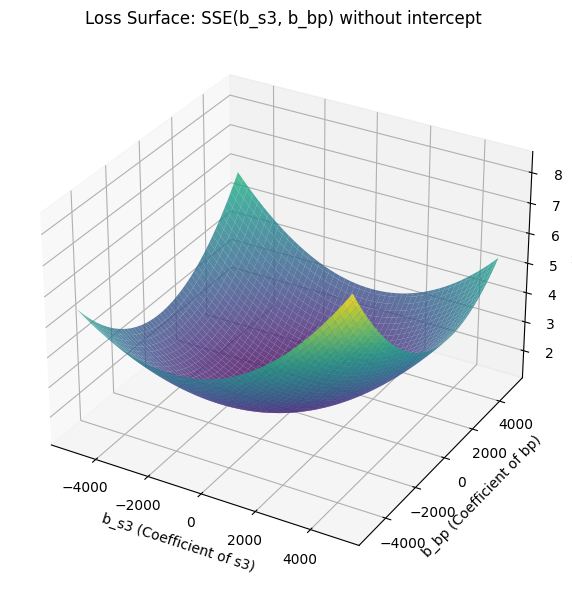

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import load_diabetes

# 1. 데이터 불러오기
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

# s3, bp 변수 선택
idx_s3 = feature_names.index('s3')
idx_bp = feature_names.index('bp')
x_s3 = X[:, idx_s3]
x_bp = X[:, idx_bp]

# 2. 계수의 탐색 범위 설정
b_s3_range = np.linspace(-5000, 5000, 100)
b_bp_range = np.linspace(-5000, 5000, 100)
B_s3, B_bp = np.meshgrid(b_s3_range, b_bp_range)

# 3. 예측값 및 손실 계산 (b0 제외)
Y_pred = B_s3[None, :, :] * x_s3[:, None, None] + B_bp[None, :, :] * x_bp[:, None, None]
SSE = np.sum((y[:, None, None] - Y_pred)**2, axis=0)

# 4. 3D 시각화
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(B_s3, B_bp, SSE, cmap='viridis', alpha=0.8)

ax.set_xlabel('b_s3 (Coefficient of s3)')
ax.set_ylabel('b_bp (Coefficient of bp)')
ax.set_zlabel('SSE')
ax.set_title('Loss Surface: SSE(b_s3, b_bp) without intercept')

plt.tight_layout()
plt.show()


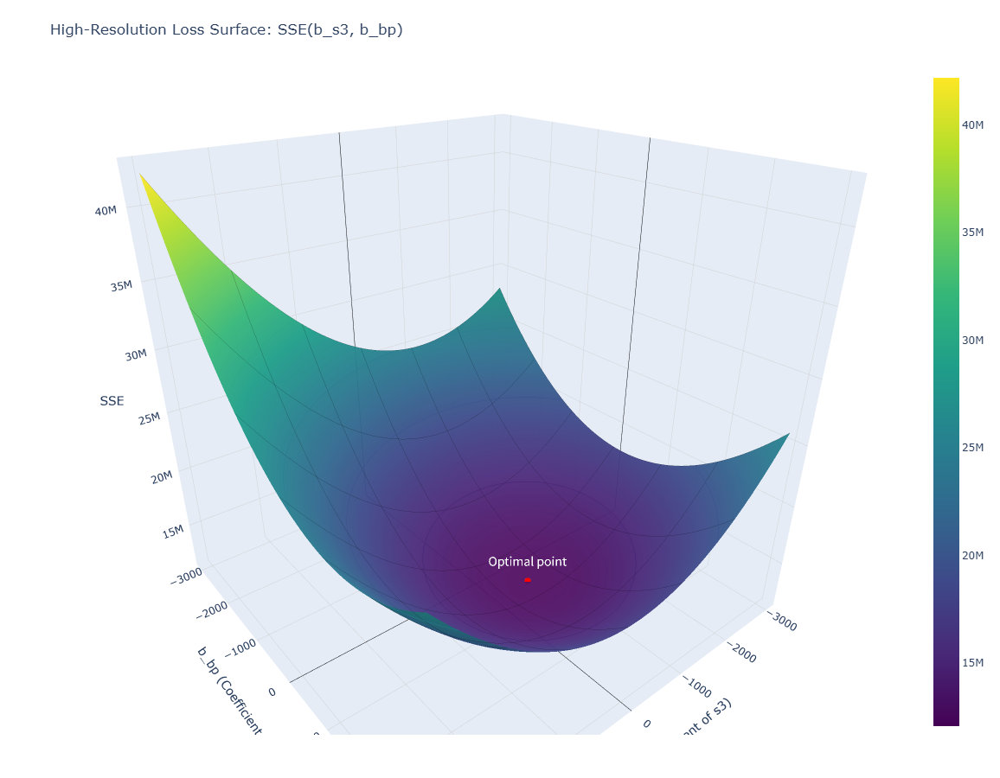

In [41]:
import numpy as np
import plotly.graph_objects as go
from sklearn.datasets import load_diabetes

# 1️⃣ 데이터 로드
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

# 2️⃣ s3, bp 변수 선택
idx_s3 = feature_names.index('s3')
idx_bp = feature_names.index('bp')
x_s3 = X[:, idx_s3]
x_bp = X[:, idx_bp]

# 3️⃣ 계수 탐색 범위 (더 촘촘하게)
b_s3_range = np.linspace(-3000, 3000, 200)  # ← 해상도 증가
b_bp_range = np.linspace(-3000, 3000, 200)
B_s3, B_bp = np.meshgrid(b_s3_range, b_bp_range)

# 4️⃣ 손실함수(SSE) 계산 (절편 제외)
Y_pred = B_s3[None, :, :] * x_s3[:, None, None] + B_bp[None, :, :] * x_bp[:, None, None]
SSE = np.sum((y[:, None, None] - Y_pred) ** 2, axis=0)

# 5️⃣ Plotly Surface
fig = go.Figure(
    data=[
        go.Surface(
            x=B_s3,
            y=B_bp,
            z=SSE,
            colorscale='Viridis',
            opacity=0.95,
            contours={
                "x": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
                "y": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
                "z": {"show": True, "color": "white", "width": 1, "usecolormap": True},
            },
        )
    ]
)

# 6️⃣ 그래프 스타일 & 사이즈 설정
fig.update_layout(
    title="High-Resolution Loss Surface: SSE(b_s3, b_bp)",
    scene=dict(
        xaxis=dict(
            title="b_s3 (Coefficient of s3)",
            showgrid=True,
            gridcolor="lightgray",
            gridwidth=1,
            zeroline=True,
            zerolinecolor="black"
        ),
        yaxis=dict(
            title="b_bp (Coefficient of bp)",
            showgrid=True,
            gridcolor="lightgray",
            gridwidth=1,
            zeroline=True,
            zerolinecolor="black"
        ),
        zaxis=dict(
            title="SSE",
            showgrid=True,
            gridcolor="lightgray",
            gridwidth=1,
        ),
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.2)  # 보기 좋은 회전 시점
        )
    ),
    width=1200,    # ← 요청하신 해상도
    height=900,
    margin=dict(l=50, r=50, b=50, t=80)
)
from sklearn.linear_model import LinearRegression

# 실제 선형회귀로 최적계수 계산
model = LinearRegression(fit_intercept=False)
X_subset = np.column_stack([x_s3, x_bp])
model.fit(X_subset, y)

b_s3_opt, b_bp_opt = model.coef_
SSE_opt = np.sum((y - (b_s3_opt * x_s3 + b_bp_opt * x_bp))**2)

# 곡면 위에 최적점 표시
fig.add_trace(go.Scatter3d(
    x=[b_s3_opt],
    y=[b_bp_opt],
    z=[SSE_opt],
    mode='markers+text',
    marker=dict(size=2, color='red', symbol='circle'),
    text=['Optimal point'],
    textposition='top center',
    textfont=dict(color='white', size=14, family='Arial Bold')
))
fig.show()


In [47]:
from sklearn.linear_model import LinearRegression
import plotly.graph_objects as go
import numpy as np
from sklearn.datasets import load_diabetes

# 1️⃣ 데이터 로드
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

idx_s3 = feature_names.index('s3')
idx_bp = feature_names.index('bp')
x_s3 = X[:, idx_s3]
x_bp = X[:, idx_bp]

# 2️⃣ 계수 범위
b_s3_range = np.linspace(-3000, 3000, 200)
b_bp_range = np.linspace(-3000, 3000, 200)
B_s3, B_bp = np.meshgrid(b_s3_range, b_bp_range)

Y_pred = B_s3[None, :, :] * x_s3[:, None, None] + B_bp[None, :, :] * x_bp[:, None, None]
SSE = np.sum((y[:, None, None] - Y_pred) ** 2, axis=0)

# 3️⃣ Surface
fig = go.Figure(
    data=[
        go.Surface(
            x=B_s3,
            y=B_bp,
            z=SSE,
            colorscale='Viridis',
            opacity=0.95,
            contours={
                "x": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
                "y": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
                "z": {"show": True, "color": "white", "width": 1, "usecolormap": True},
            },
        )
    ]
)

# 4️⃣ 실제 최적점 계산
model = LinearRegression(fit_intercept=False)
X_subset = np.column_stack([x_s3, x_bp])
model.fit(X_subset, y)
b_s3_opt, b_bp_opt = model.coef_
SSE_opt = np.sum((y - (b_s3_opt * x_s3 + b_bp_opt * x_bp))**2)

# 5️⃣ 최적점 표시 (텍스트 흰색)
fig.add_trace(go.Scatter3d(
    x=[b_s3_opt],
    y=[b_bp_opt],
    z=[SSE_opt],
    mode='markers+text',
    marker=dict(size=3, color='red', symbol='circle'),
    text=['Optimal point'],
    textposition='top center',
    textfont=dict(color='white', size=14, family='Arial Bold')
))

# 6️⃣ 가이드라인 추가 (X, Y, Z 축 기준)
line_color = "rgba(255,0,0,0.3)"  # 반투명 흰색

# X축 방향 (b_s3)
fig.add_trace(go.Scatter3d(
    x=[b_s3_range.min(), b_s3_range.max()],
    y=[b_bp_opt, b_bp_opt],
    z=[SSE_opt, SSE_opt],
    mode="lines",
    line=dict(color=line_color, width=3),
    showlegend=False
))

# Y축 방향 (b_bp)
fig.add_trace(go.Scatter3d(
    x=[b_s3_opt, b_s3_opt],
    y=[b_bp_range.min(), b_bp_range.max()],
    z=[SSE_opt, SSE_opt],
    mode="lines",
    line=dict(color=line_color, width=3),
    showlegend=False
))

# Z축 방향 (SSE)
fig.add_trace(go.Scatter3d(
    x=[b_s3_opt, b_s3_opt],
    y=[b_bp_opt, b_bp_opt],
    z=[SSE.min(), SSE_opt],
    mode="lines",
    line=dict(color="red", width=4, dash="dash"),
    showlegend=False
))

# 7️⃣ 레이아웃
fig.update_layout(
    title="Loss Surface with Optimal Point and Guide Lines",
    scene=dict(
        xaxis_title="b_s3 (Coefficient of s3)",
        yaxis_title="b_bp (Coefficient of bp)",
        zaxis_title="SSE",
        xaxis=dict(showgrid=True, gridcolor='lightgray'),
        yaxis=dict(showgrid=True, gridcolor='lightgray'),
        zaxis=dict(showgrid=True, gridcolor='lightgray'),
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
    ),
    width=1600,
    height=1200,
    margin=dict(l=50, r=50, b=50, t=80)
)

fig.show()


Iter 1: b_bp=3798.02, b_s3=-3668.00, SSE=25363016.89
Iter 2: b_bp=-2633.03, b_s3=2709.41, SSE=26672596.86
Iter 3: b_bp=3958.19, b_s3=-3859.68, SSE=28055548.45
Iter 4: b_bp=-2807.29, b_s3=2896.67, SSE=29515597.03
Iter 5: b_bp=4141.24, b_s3=-4048.09, SSE=31056975.05
Iter 6: b_bp=-2997.01, b_s3=3088.60, SSE=32684201.67
Iter 7: b_bp=4336.85, b_s3=-4244.61, SSE=34402056.40
Iter 8: b_bp=-3198.27, b_s3=3290.24, SSE=36215586.45
Iter 9: b_bp=4543.75, b_s3=-4451.67, SSE=38130120.37
Iter 10: b_bp=-3410.91, b_s3=3502.94, SSE=40151283.52


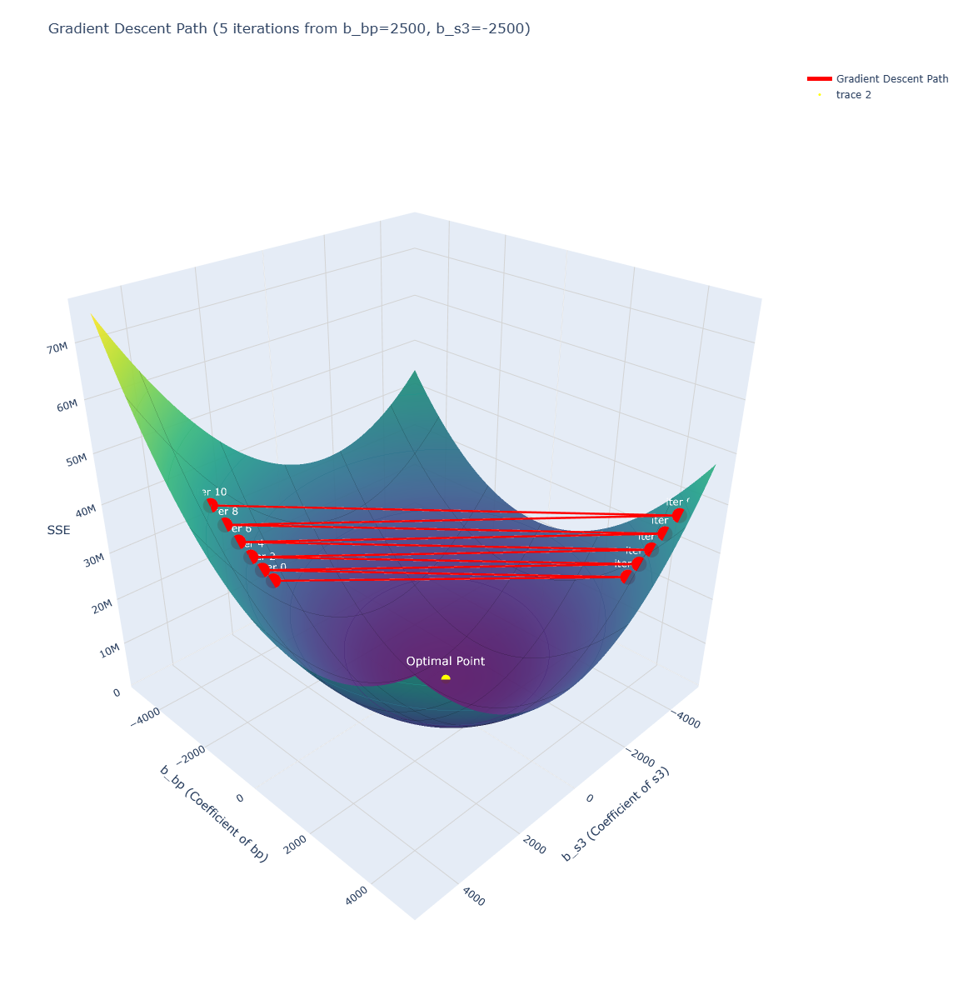

In [23]:
import numpy as np
import plotly.graph_objects as go
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

# 1️⃣ 데이터 불러오기
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

idx_bp = feature_names.index('bp')
idx_s3 = feature_names.index('s3')
x_bp = X[:, idx_bp]
x_s3 = X[:, idx_s3]
n = len(y)

# 2️⃣ b0(절편)은 고정 (LinearRegression으로 미리 계산)
model = LinearRegression()
model.fit(np.column_stack([x_bp, x_s3]), y)
b0_opt = model.intercept_

# 3️⃣ 손실(SSE) 계산 함수
def compute_sse(b_bp, b_s3):
    y_pred = b0_opt + b_bp * x_bp + b_s3 * x_s3
    return np.sum((y - y_pred) ** 2)

# 4️⃣ 경사(gradient) 계산 함수
def compute_gradients(b_bp, b_s3):
    y_pred = b0_opt + b_bp * x_bp + b_s3 * x_s3
    residual = y - y_pred
    grad_bp = -2 * np.sum(x_bp * residual)
    grad_s3 = -2 * np.sum(x_s3 * residual)
    return grad_bp, grad_s3

# 5️⃣ 경사하강 초기 설정
b_bp, b_s3 = -2500.0, 2500.0
lr = 0.86                   # 학습률
iterations = 10

b_bp_path, b_s3_path, sse_path = [b_bp], [b_s3], [compute_sse(b_bp, b_s3)]

for i in range(iterations):
    grad_bp, grad_s3 = compute_gradients(b_bp, b_s3)
    b_bp -= lr * grad_bp
    b_s3 -= lr * grad_s3
    sse = compute_sse(b_bp, b_s3)
    b_bp_path.append(b_bp)
    b_s3_path.append(b_s3)
    sse_path.append(sse)
    print(f"Iter {i+1}: b_bp={b_bp:.2f}, b_s3={b_s3:.2f}, SSE={sse:.2f}")

# 6️⃣ 손실곡면 계산
b_bp_range = np.linspace(-5000, 5000, 200)
b_s3_range = np.linspace(-5000, 5000, 200)
B_BP, B_S3 = np.meshgrid(b_bp_range, b_s3_range)
Y_pred = b0_opt + B_BP[None, :, :] * x_bp[:, None, None] + B_S3[None, :, :] * x_s3[:, None, None]
SSE = np.sum((y[:, None, None] - Y_pred) ** 2, axis=0)

# 7️⃣ Plotly 시각화
fig = go.Figure()

# 손실 곡면
fig.add_trace(go.Surface(
    x=b_s3_range,
    y=b_bp_range,
    z=SSE.T,
    colorscale="Viridis",
    opacity=0.9,
    showscale=False,
    contours={
        "x": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
        "y": {"show": True, "color": "rgba(0,0,0,0.3)", "width": 1},
        "z": {"show": True, "color": "white", "width": 1, "usecolormap": True},
    },
))

# 경사하강 경로 (빨간 선)
fig.add_trace(go.Scatter3d(
    x=b_s3_path,
    y=b_bp_path,
    z=sse_path,
    mode="lines+markers+text",
    line=dict(color="red", width=5),
    marker=dict(size=5, color="red"),
    text=[f"iter {i}" for i in range(len(sse_path))],
    textposition="top center",
    textfont=dict(color="white", size=12),
    name="Gradient Descent Path"
))

# 최적점 표시 (노란 점)
b_bp_opt, b_s3_opt = model.coef_
sse_opt = compute_sse(b_bp_opt, b_s3_opt)
fig.add_trace(go.Scatter3d(
    x=[b_s3_opt], y=[b_bp_opt], z=[sse_opt],
    mode="markers+text",
    marker=dict(size=3, color="yellow"),
    text=["Optimal Point"],
    textfont=dict(color="white", size=14),
    textposition="top center"
))

# 레이아웃
fig.update_layout(
    title="Gradient Descent Path (5 iterations from b_bp=2500, b_s3=-2500)",
    scene=dict(
        xaxis_title="b_s3 (Coefficient of s3)",
        yaxis_title="b_bp (Coefficient of bp)",
        zaxis_title="SSE",
        xaxis=dict(showgrid=True, gridcolor='lightgray'),
        yaxis=dict(showgrid=True, gridcolor='lightgray'),
        zaxis=dict(showgrid=True, gridcolor='lightgray'),
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
    ),
    width=1600,
    height=1200,
    margin=dict(l=50, r=50, b=50, t=80)
)

fig.show()
